# M203 - Estadística descriptiva e inferencial aplicada

> Módulo II - Data Science
>
> Tema 4: Estadística descriptiva e inferencial aplicada

Contenido:

1. Caracterización de los conjuntos de datos
2. Análisis de datos continuos y distribuciones
3. Análisis de datos discretos y categorías/clases
4. Modelo descriptivo
5. Modelo inferencial

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [2]:
iris = pandas.read_csv("./conjuntos/iris.csv")

iris

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


La flor iris se divide en 3 especies/familias que son Virgínica, Versicolor y la Setosa.

En el conjunto de datos tenemos 150 observaciones anotadas sobre diferentes flores con sus tamaños de largo y ancho de sépalo y pétalo.

![iris1](imagenes/iris1.png)

El conjunto de datos anota en 5 columnas las mediciones, 4 referentes a los tamaños (variables continuas) y una más para la variedad (discreta).

![iris2](imagenes/iris2.jpeg)

El conjunto de datos genera un problema tanto de regresión como de clasificación para problemas de Aprendizaje Supervisado.

![iris3](imagenes/iris3.jpg)

## 1. Caracterización del conjunto de datos

* Definir las características como ejes de datos/información que permitan su análisis individual (continuo o discreto)
* Observar su comportamiento numérico o categórico

In [45]:
c1 = iris["sepal.length"] # Largo del sépalo
c2 = iris["sepal.width"] # Ancho del sépalo
c3 = iris["petal.length"] # Largo del pétalo
c4 = iris["petal.width"] # Ancho del pétalo
c5 = iris["variety"] # Variedad

In [4]:
# Informar la estructura de los datos

c1.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: sepal.length
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [5]:
c2.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: sepal.width
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [6]:
c3.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: petal.length
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [7]:
c4.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: petal.width
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [8]:
c5.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: variety
Non-Null Count  Dtype
--------------  -----
150 non-null    str  
dtypes: str(1)
memory usage: 1.3 KB


## 2. Análisis de datos continuos y distribuciones

> Supuestos

1. Suponemos que los valor son numéricos
2. Suponemos que los datos se encuentran distribuidos entre un valor mínimo y máximo observados, es decir, no hay valores faltantes
3. Suponemos que su distribución es uniforme o normal (sesgada o insesgada), pero no múlti-pico, es decir, que solo hay a lo más un solo montículo de centralidad en su distribución

In [13]:
# La siguiente serie cumple los supuestos

edades1 = pandas.Series([25, 26, 24, 28, 30, 15, 19, 18, 20, 22, 24, 23, 24, 25, 26, 25, 25, 25])

edades1.sort_values()

5     15
7     18
6     19
8     20
9     22
11    23
2     24
12    24
10    24
15    25
13    25
0     25
16    25
17    25
14    26
1     26
3     28
4     30
dtype: int64

<Axes: ylabel='Density'>

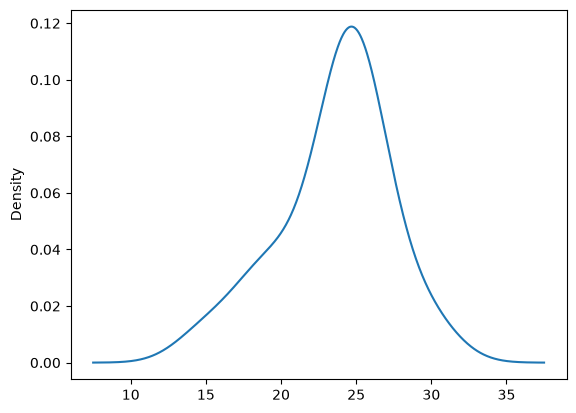

In [14]:
edades1.plot.density()

<Axes: ylabel='Density'>

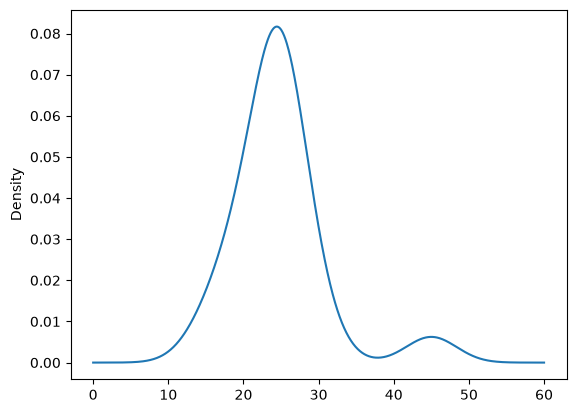

In [16]:
# La siguiente serie no cumple los supuestos

edades2 = pandas.Series([25, 26, 24, 28, 30, 45, 15, 19, 18, 20, 22, 24, 23, 24, 25, 26, 25, 25, 25])

edades2.plot.density()

<Axes: ylabel='Density'>

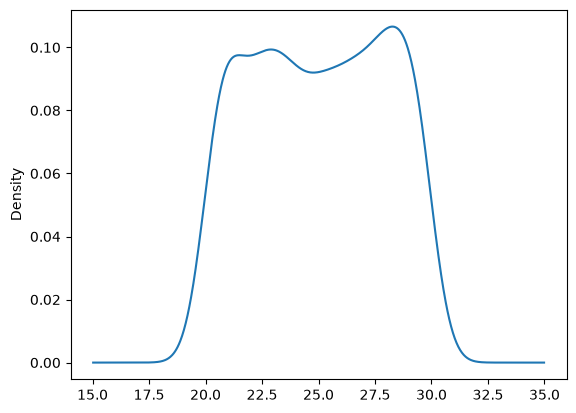

In [23]:
# La siguiente serie cumple los supuestos

edades3 = pandas.Series(
    numpy.random.uniform(20, 30, 1000)
)

edades3.plot.density()

La normalidad de los datos implica supuestos/restricciones todavía más fuertes, en los que se buscan distribuciones aproximadamente normales:

* La distribución de los datos están centrados en un único valor (promedio/media) y se alejan de esa media con probabilidad o densidad cada vez menor, entonces, la probabilidad de encontrar un valor lejano a ese punto/pico centra de la distribución es cada vez menor
* La densidad debe observarse lo más simétrica posible (sino se dirá sesgada hacía izquierda o la derecha)
* El modelo normal aproxima una densidad en forma de campana y se conoce como la distribución gaussiana

$$
f(x) = \frac{1}{\sqrt{\pi \sigma^2}} e^{-\frac{(x - \mu)^2}{\sigma^2}}
$$

Donde $\mu$ es el promedio o media poblacional (puede ser estima en la práctica, si se valida con una prueba de hipótesis el p-valor) y $\sigma$ es la desviación estándar (o $\sigma^2$ es la varianza que también puede ser estimada con los datos y validad con una prueba F).

In [28]:
x = edades1

mu = x.mean()
sigma = x.std()

f = lambda xi: numpy.exp(-(xi - mu) ** 2 / sigma ** 2) / (numpy.pi * sigma ** 2) ** 0.5

y = [f(xi) for xi in x]

pandas.DataFrame({
    "x": x,
    "y": y
}).sort_values("x")

,x,y
5,15,0.000607
7,18,0.014991
6,19,0.032243
8,20,0.059599
9,22,0.129270
11,23,0.151685
2,24,0.152967
12,24,0.152967
10,24,0.152967
15,25,0.132575


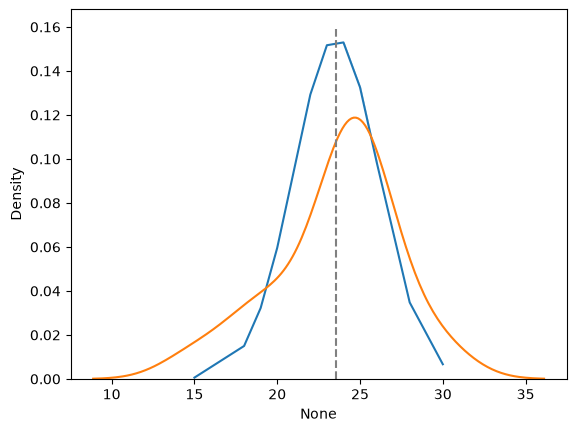

In [33]:
seaborn.lineplot(x=x, y=y) # Normal ideal
seaborn.kdeplot(x=x) # KDE
pyplot.vlines(mu, 0, 0.16, color="gray", linestyle="--")

In [34]:
x.describe()

count    18.000000
mean     23.555556
std       3.633540
min      15.000000
25%      22.250000
50%      24.500000
75%      25.000000
max      30.000000
dtype: float64

### Análisis del largo de sépalo ($c_1$)

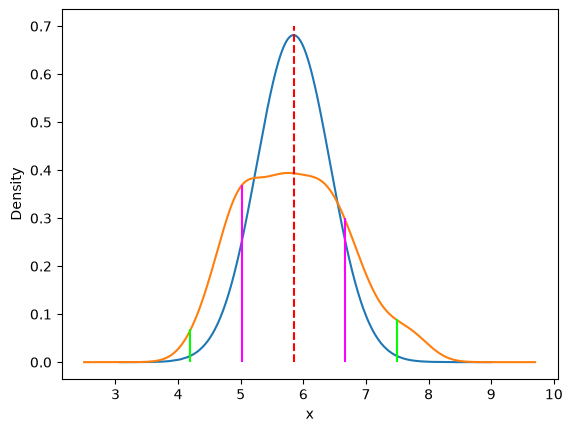

In [66]:
# Una muestra de 1,000 observaciones aleatorias
# similares a C1 - Largo de sépalo (con misma media y desviación estándar)
x_normal = numpy.random.normal(c1.mean(), c1.std(), 1000)
# Curva normal del modelo f(x) = e^-(x - mu) ...
y_normal = numpy.exp(-(x_normal - c1.mean()) ** 2 / c1.var()) / \
            (numpy.pi * c1.var()) ** 0.5
# Curva de muestras aleatorias similares
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
# Curva estimada para nuestros datos reales
c1.plot.density() # KDE
# Dibujamos las anotaciones estadísticas
pyplot.vlines(c1.mean(), 0, 0.7, color="red", linestyle="--")
pyplot.vlines(c1.mean() + c1.std(), 0, 0.3, color="magenta", linestyle="-")
pyplot.vlines(c1.mean() - c1.std(), 0, 0.37, color="magenta", linestyle="-")
pyplot.vlines(c1.mean() + 2 * c1.std(), 0, 0.09, color="lime", linestyle="-")
pyplot.vlines(c1.mean() - 2 * c1.std(), 0, 0.07, color="lime", linestyle="-")

Puntos de observación:

1. La curva estima está menos densa en el centro (tiene densidad más baja), es decir, los datos no son tan centrales a la media
2. Tenemos colas pesadas que indican posibles sesgos hacia los extremos de izquierda y derecha, es decir, hay posibles diferencias entre grupos no identificados

In [48]:
# Estasdísticos para C1 - Largo del sépalo

c1.describe()

count    150.000000
mean       5.843333
std        0.828066
min        4.300000
25%        5.100000
50%        5.800000
75%        6.400000
max        7.900000
Name: sepal.length, dtype: float64

En una distribución normal, podemos estimar cuántos datos serán cubiertos en un intervalor que se aleja de la media con razón de la desviación estándar:

$$
I_{covertura}: (\mu - i \sigma, \mu + i \sigma)
$$

![normal1](imagenes/normal1.png)

In [71]:
# Intervalos de covertura para C1 - Largo del sépalo

pandas.DataFrame({
    "68%": [c1.mean() - 1 * c1.std(), c1.mean() + 1 * c1.std()],
    "95%": [c1.mean() - 2 * c1.std(), c1.mean() + 2 * c1.std()],
    "99.7%": [c1.mean() - 3 * c1.std(), c1.mean() + 3 * c1.std()],
}, index=["-i * sigma", "+i * sigma"]).T

,-i * sigma,+i * sigma
68%,5.015267,6.671399
95%,4.187201,7.499466
99.7%,3.359135,8.327532


In [79]:
print(f"68% | {100 * c1[(c1 >= 5.0152) & (c1 <= 6.6714)].count() / c1.count():.0f}%")
print(f"95% | {100 * c1[(c1 >= 4.1872) & (c1 <= 7.5)].count() / c1.count():.0f}%")
print(f"99.7% | {100 * c1[(c1 >= 3.3591) & (c1 <= 8.3275)].count() / c1.count():.0f}%")

68% | 60%
95% | 96%
99.7% | 100%


### Análisis del ancho de sépalo ($c_2$)

count    150.000000
mean       3.057333
std        0.435866
min        2.000000
25%        2.800000
50%        3.000000
75%        3.300000
max        4.400000
Name: sepal.width, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      2.621467    3.493200
95%      2.185601    3.929066
99.7%    1.749734    4.364932
------------------------------------------------------------
68% | 67%
95% | 97%
99.7% | 99%
------------------------------------------------------------


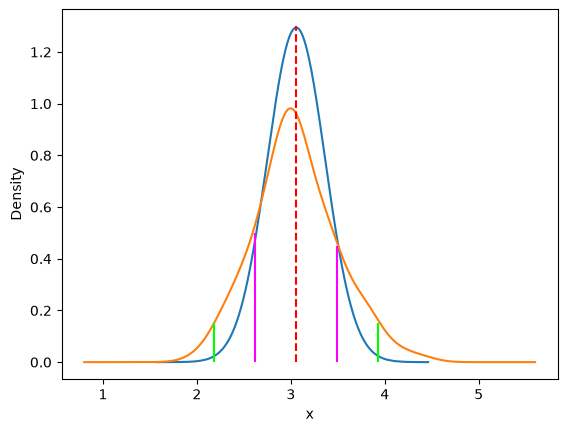

In [98]:
print(c2.describe())
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c2.mean() - 1 * c2.std(), c2.mean() + 1 * c2.std()],
    "95%": [c2.mean() - 2 * c2.std(), c2.mean() + 2 * c2.std()],
    "99.7%": [c2.mean() - 3 * c2.std(), c2.mean() + 3 * c2.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c2[(c2 >= intervalos.iloc[0, 0]) & (c2 <= intervalos.iloc[0, 1])].count() / c2.count():.0f}%")
print(f"95% | {100 * c2[(c2 >= intervalos.iloc[1, 0]) & (c2 <= intervalos.iloc[1, 1])].count() / c2.count():.0f}%")
print(f"99.7% | {100 * c2[(c2 >= intervalos.iloc[2, 0]) & (c2 <= intervalos.iloc[2, 1])].count() / c2.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c2.mean(), c2.std(), 1000)
y_normal = numpy.exp(-(x_normal - c2.mean()) ** 2 / c2.var()) / \
            (numpy.pi * c2.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c2.plot.density() # KDE
pyplot.vlines(c2.mean(), 0, 1.3, color="red", linestyle="--")
pyplot.vlines(c2.mean() - c2.std(), 0, 0.5, color="magenta", linestyle="-")
pyplot.vlines(c2.mean() + c2.std(), 0, 0.45, color="magenta", linestyle="-")
pyplot.vlines(c2.mean() - 2 * c2.std(), 0, 0.15, color="lime", linestyle="-")
pyplot.vlines(c2.mean() + 2 * c2.std(), 0, 0.15, color="lime", linestyle="-")
pyplot.show()

### Análisis del largo de pétalo ($c_3$)

count    150.000000
mean       3.758000
std        1.765298
min        1.000000
25%        1.600000
50%        4.350000
75%        5.100000
max        6.900000
Name: petal.length, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      1.992702    5.523298
95%      0.227404    7.288596
99.7%   -1.537895    9.053895
------------------------------------------------------------
68% | 50%
95% | 100%
99.7% | 100%
------------------------------------------------------------


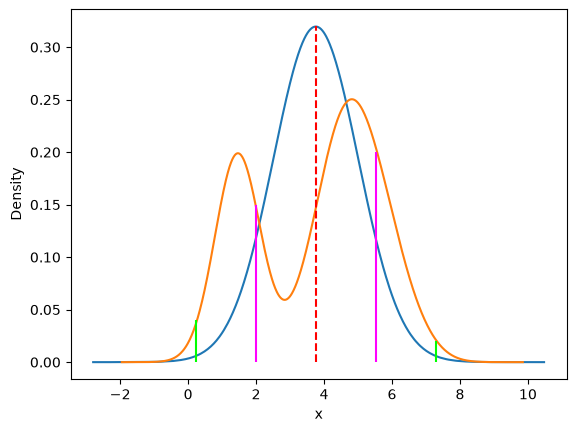

In [109]:
print(c3.describe())
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c3.mean() - 1 * c3.std(), c3.mean() + 1 * c3.std()],
    "95%": [c3.mean() - 2 * c3.std(), c3.mean() + 2 * c3.std()],
    "99.7%": [c3.mean() - 3 * c3.std(), c3.mean() + 3 * c3.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c3[(c3 >= intervalos.iloc[0, 0]) & (c3 <= intervalos.iloc[0, 1])].count() / c3.count():.0f}%")
print(f"95% | {100 * c3[(c3 >= intervalos.iloc[1, 0]) & (c3 <= intervalos.iloc[1, 1])].count() / c3.count():.0f}%")
print(f"99.7% | {100 * c3[(c3 >= intervalos.iloc[2, 0]) & (c3 <= intervalos.iloc[2, 1])].count() / c3.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c3.mean(), c3.std(), 1000)
y_normal = numpy.exp(-(x_normal - c3.mean()) ** 2 / c3.var()) / \
            (numpy.pi * c3.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c3.plot.density() # KDE
pyplot.vlines(c3.mean(), 0, 0.32, color="red", linestyle="--")
pyplot.vlines(c3.mean() - c3.std(), 0, 0.15, color="magenta", linestyle="-")
pyplot.vlines(c3.mean() + c3.std(), 0, 0.2, color="magenta", linestyle="-")
pyplot.vlines(c3.mean() - 2 * c3.std(), 0, 0.04, color="lime", linestyle="-")
pyplot.vlines(c3.mean() + 2 * c3.std(), 0, 0.02, color="lime", linestyle="-")
pyplot.show()

### Análisis del ancho de pétalo ($c_4$)

count    150.000000
mean       1.199333
std        0.762238
min        0.100000
25%        0.300000
50%        1.300000
75%        1.800000
max        2.500000
Name: petal.width, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      0.437096    1.961571
95%     -0.325142    2.723809
99.7%   -1.087380    3.486046
------------------------------------------------------------
68% | 49%
95% | 100%
99.7% | 100%
------------------------------------------------------------


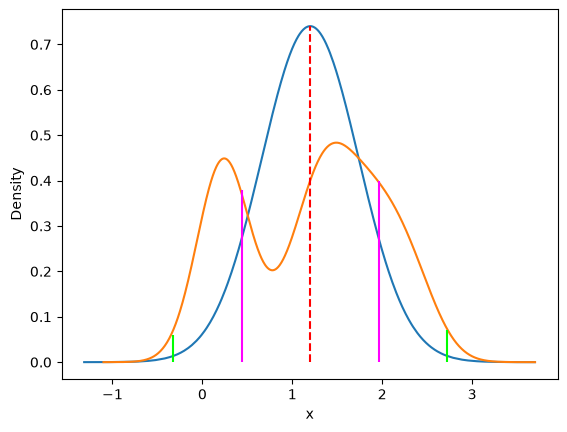

In [119]:
print(c4.describe()) # RECESO DE 11:00 a 11:20
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c4.mean() - 1 * c4.std(), c4.mean() + 1 * c4.std()],
    "95%": [c4.mean() - 2 * c4.std(), c4.mean() + 2 * c4.std()],
    "99.7%": [c4.mean() - 3 * c4.std(), c4.mean() + 3 * c4.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c4[(c4 >= intervalos.iloc[0, 0]) & (c4 <= intervalos.iloc[0, 1])].count() / c4.count():.0f}%")
print(f"95% | {100 * c4[(c4 >= intervalos.iloc[1, 0]) & (c4 <= intervalos.iloc[1, 1])].count() / c4.count():.0f}%")
print(f"99.7% | {100 * c4[(c4 >= intervalos.iloc[2, 0]) & (c4 <= intervalos.iloc[2, 1])].count() / c4.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c4.mean(), c4.std(), 1000)
y_normal = numpy.exp(-(x_normal - c4.mean()) ** 2 / c4.var()) / \
            (numpy.pi * c4.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c4.plot.density() # KDE
pyplot.vlines(c4.mean(), 0, 0.74, color="red", linestyle="--")
pyplot.vlines(c4.mean() - c4.std(), 0, 0.38, color="magenta", linestyle="-")
pyplot.vlines(c4.mean() + c4.std(), 0, 0.4, color="magenta", linestyle="-")
pyplot.vlines(c4.mean() - 2 * c4.std(), 0, 0.06, color="lime", linestyle="-")
pyplot.vlines(c4.mean() + 2 * c4.std(), 0, 0.07, color="lime", linestyle="-")
pyplot.show()

## 3. Análisis de datos discretos y categorías/clases

> Supuestos

1. Suponemos que los datos aunque sean numéricos generalmente no serán continuos (datos enteros), o si los datos directamente forman categorías en forma de texto, valores lógicos o de otras naturalezas
2. Suponemos que los valores forman grupos o clases que representan relaciones, pertenencias, efectos o contextos que determinan que el valor forma parte de grupos repetidos en las observaciones
3. Suponemos que los grupos/clases tienen proporciones similares, evitando que una categoría sea tan pequeña respecto a las demás (problema de desbalance de clases)

### Análisis de la variedad ($c_5$)

In [120]:
c5.describe()

count        150
unique         3
top       Setosa
freq          50
Name: variety, dtype: object

In [123]:
c5.value_counts() # Soportes

variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

In [124]:
c5.value_counts(normalize=True)

variety
Setosa        0.333333
Versicolor    0.333333
Virginica     0.333333
Name: proportion, dtype: float64

<Axes: ylabel='variety'>

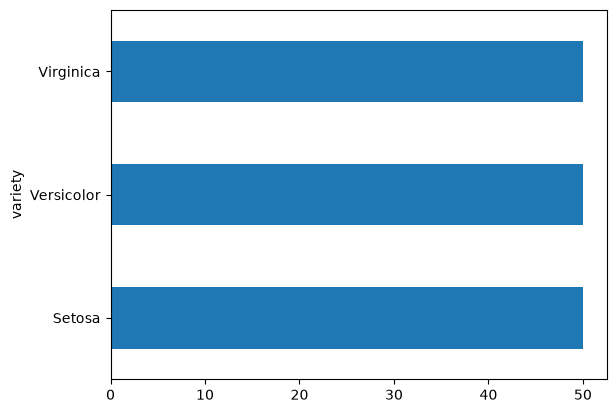

In [129]:
c5.value_counts().plot.barh() # s:vc:vg 50:50:50 (1:1:1)

### Segmegmentación o partición del espacio de datos

* Cada clase parte o separa/segmenta los datos que se tienen en otras variables tanto continuas como discretas
* Cada grupo se puede analizar para determinar si hay diferencias entre grupos (ANOVA - Análisis de varianza entre grupos)
* Los grupos podrían dar normalidad a los datos (explicar las variaciones de los picos en las distribuciones que no estaban explicadas)

In [131]:
c5.unique() # Identificamos las 3-clases (setosa, versicolor y virgínica)

<StringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str

In [132]:
c1_setosa = c1[c5 == 'Setosa'] # Aplicamos un filtro o segmento (máscara de los que son Setosa)

In [139]:
pandas.DataFrame({
    "Variedad": c5,
    "Setosa": c5 == "Setosa", # Máscara lógica
    "Versicolor": c5 == "Versicolor", # Máscara lógica
    "Virgínica": c5 == "Virginica", # Máscara lógica
}).sample(20) # Espacio de Dummies (clases codificadas / pertenencia a cada clase)

,Variedad,Setosa,Versicolor,Virgínica
43,Setosa,True,False,False
130,Virginica,False,False,True
15,Setosa,True,False,False
72,Versicolor,False,True,False
86,Versicolor,False,True,False
139,Virginica,False,False,True
111,Virginica,False,False,True
0,Setosa,True,False,False
137,Virginica,False,False,True
71,Versicolor,False,True,False


In [141]:
pandas.DataFrame({
    "Variedad": c5,
    "Setosa": (c5 == "Setosa").astype(int), # Máscara lógica
    "Versicolor": (c5 == "Versicolor").astype(int), # Máscara lógica
    "Virgínica": (c5 == "Virginica").astype(int), # Máscara lógica
}).sample(20) # Espacio de codificación One-Hot (espacio de activación / clúster binario)

,Variedad,Setosa,Versicolor,Virgínica
46,Setosa,1,0,0
55,Versicolor,0,1,0
45,Setosa,1,0,0
82,Versicolor,0,1,0
39,Setosa,1,0,0
57,Versicolor,0,1,0
89,Versicolor,0,1,0
58,Versicolor,0,1,0
137,Virginica,0,0,1
97,Versicolor,0,1,0


In [142]:
c1_setosa = c1[c5 == "Setosa"]
c1_versicolor = c1[c5 == "Versicolor"]
c1_virginica = c1[c5 == "Virginica"]

c2_setosa = c2[c5 == "Setosa"]
c2_versicolor = c2[c5 == "Versicolor"]
c2_virginica = c2[c5 == "Virginica"]

c3_setosa = c3[c5 == "Setosa"]
c3_versicolor = c3[c5 == "Versicolor"]
c3_virginica = c3[c5 == "Virginica"]

c4_setosa = c4[c5 == "Setosa"]
c4_versicolor = c4[c5 == "Versicolor"]
c4_virginica = c4[c5 == "Virginica"]

In [152]:
personas = pandas.DataFrame({
     "sexo": ["hombre", "mujer", "mujer", "hombre", "hombre", "hombre", "mujer"],
     "estatura": [1.98, 1.52, 1.58, 1.81, 1.9, 1.95, 1.51]
 })

personas

,sexo,estatura
0,hombre,1.98
1,mujer,1.52
2,mujer,1.58
3,hombre,1.81
4,hombre,1.90
5,hombre,1.95
6,mujer,1.51


<Axes: ylabel='Density'>

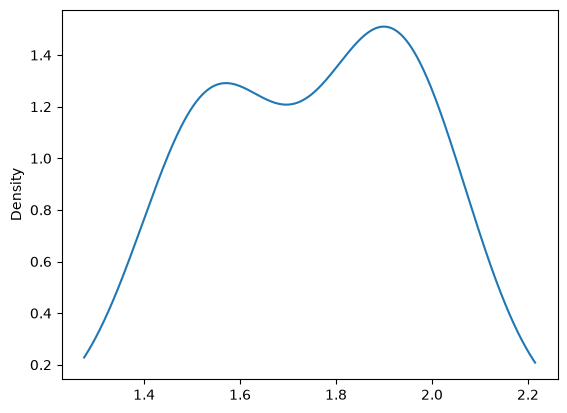

In [153]:
personas["estatura"].plot.density()

In [154]:
personas["sexo"].value_counts()

sexo
hombre    4
mujer     3
Name: count, dtype: int64

<Axes: ylabel='Density'>

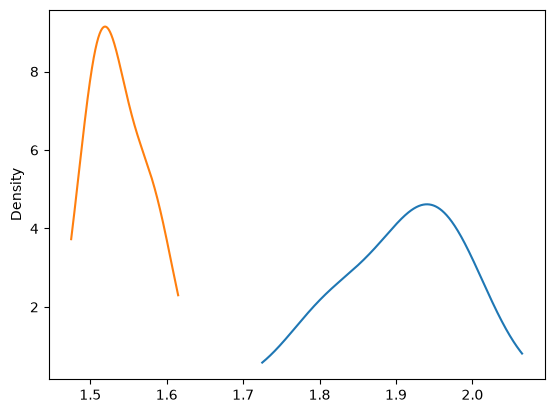

In [157]:
estaturas_hombres = personas["estatura"][personas["sexo"] == "hombre"]
estaturas_mujeres = personas["estatura"][personas["sexo"] == "mujer"]

estaturas_hombres.plot.density()
estaturas_mujeres.plot.density()

<Axes: >

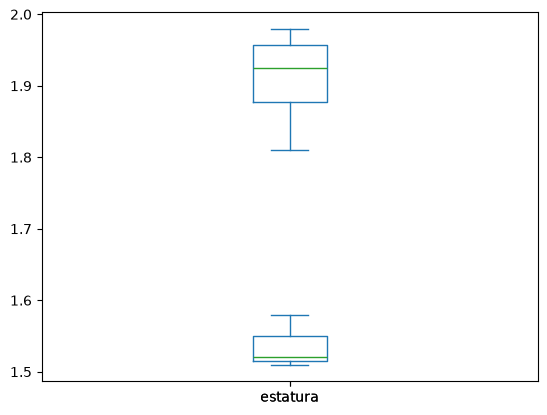

In [158]:
estaturas_hombres.plot.box()
estaturas_mujeres.plot.box()

<Axes: ylabel='estatura'>

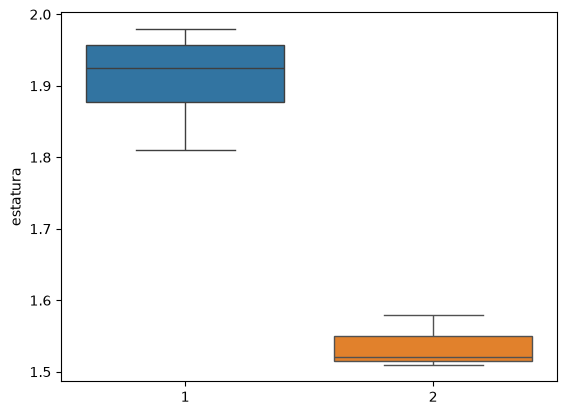

In [160]:
seaborn.boxplot(x=1, y=estaturas_hombres)
seaborn.boxplot(x=2, y=estaturas_mujeres)

<Axes: ylabel='estatura'>

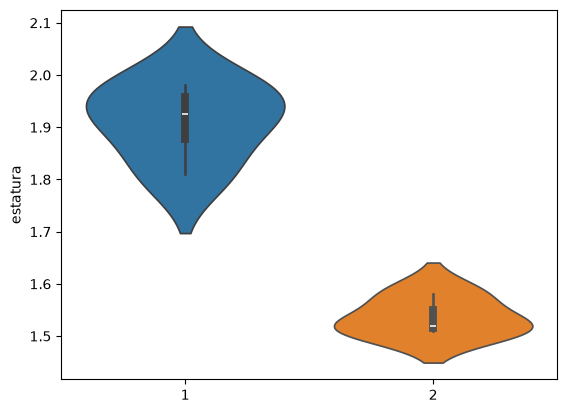

In [161]:
seaborn.violinplot(x=1, y=estaturas_hombres)
seaborn.violinplot(x=2, y=estaturas_mujeres)

<Axes: ylabel='sepal.length'>

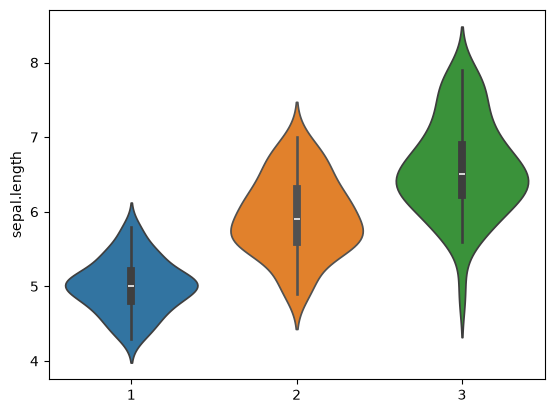

In [162]:
# C1 - Largo de sépalo
seaborn.violinplot(x=1, y=c1_setosa)
seaborn.violinplot(x=2, y=c1_versicolor)
seaborn.violinplot(x=3, y=c1_virginica)

<Axes: ylabel='sepal.length'>

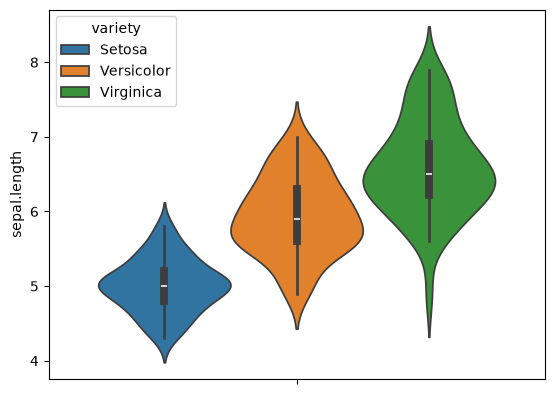

In [164]:
seaborn.violinplot(y=c1, hue=c5)

<Axes: ylabel='sepal.width'>

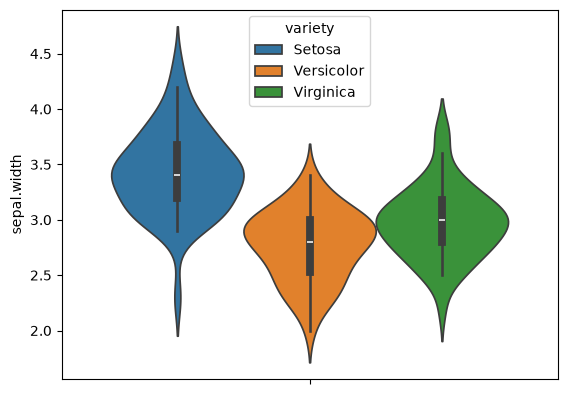

In [165]:
seaborn.violinplot(y=c2, hue=c5)

<Axes: ylabel='petal.length'>

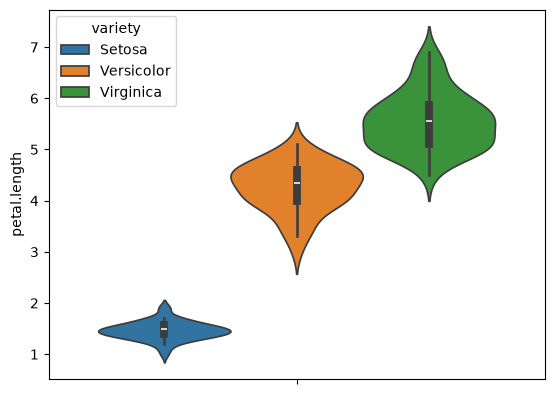

In [166]:
seaborn.violinplot(y=c3, hue=c5)

<Axes: ylabel='petal.width'>

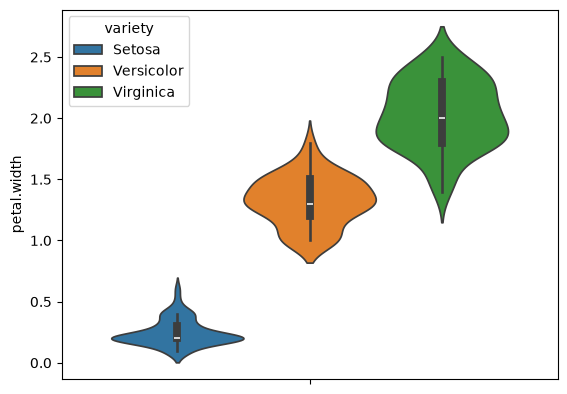

In [168]:
seaborn.violinplot(y=c4, hue=c5)

## 4. Modelo descriptivo

In [171]:
pandas.DataFrame({
    "variety": c5,
    "sepal.length": c1,
    "sepal.width": c2,
    "petal.length": c3,
    "petal.width": c4,
}).groupby("variety").mean()

,sepal.length,sepal.width,petal.length,petal.width
variety,,,,
Setosa,5.006,3.428,1.462,0.246
Versicolor,5.936,2.770,4.260,1.326
Virginica,6.588,2.974,5.552,2.026


In [172]:
pandas.DataFrame({
    "variety": c5,
    "sepal.length": c1,
    "sepal.width": c2,
    "petal.length": c3,
    "petal.width": c4,
}).groupby("variety").std()

,sepal.length,sepal.width,petal.length,petal.width
variety,,,,
Setosa,0.352490,0.379064,0.173664,0.105386
Versicolor,0.516171,0.313798,0.469911,0.197753
Virginica,0.635880,0.322497,0.551895,0.274650


In [191]:
MU = pandas.DataFrame({
    "variety": c5,
    "sepal.length": c1,
    "sepal.width": c2,
    "petal.length": c3,
    "petal.width": c4,
}).groupby("variety").mean()

SIGMA = pandas.DataFrame({
    "variety": c5,
    "sepal.length": c1,
    "sepal.width": c2,
    "petal.length": c3,
    "petal.width": c4,
}).groupby("variety").std()

SEPARADOR = pandas.DataFrame({
    "Setosa": [" - ", " - ", " - ", " - "],
    "Versicolor": [" - ", " - ", " - ", " - "],
    "Virginica": [" - ", " - ", " - ", " - "],
}, index=["sepal.length", "sepal.width", "petal.length", "petal.width"]).T

(MU - 2 * SIGMA).round(2).astype(str) + SEPARADOR + MU.round(2).astype(str) + SEPARADOR + (MU + 2 * SIGMA).round(2).astype(str)

,sepal.length,sepal.width,petal.length,petal.width
variety,,,,
Setosa,4.3 - 5.01 - 5.71,2.67 - 3.43 - 4.19,1.11 - 1.46 - 1.81,0.04 - 0.25 - 0.46
Versicolor,4.9 - 5.94 - 6.97,2.14 - 2.77 - 3.4,3.32 - 4.26 - 5.2,0.93 - 1.33 - 1.72
Virginica,5.32 - 6.59 - 7.86,2.33 - 2.97 - 3.62,4.45 - 5.55 - 6.66,1.48 - 2.03 - 2.58


In [ ]:
# Observación: (SL: 5, SW: 3, PL: 2, PW: 1.5)

## 5. Modelo inferencial

Si un eje es continuo y se distribuye de forma normal, entonces, podemos calcular la probabilidad de que ese valor se encuentre cercano a la media, es decir, la probabilidad de que un valor se parezca a la media.

En el modelo descriptivo separamos los valores de cada eje en clases/grupos, para que cada clase se comporte de manera normal (supuesto), si el supuesto se cumple, entonces, podemos calcular o inferir **qué tan probable es que un valor para una característica se parezca a la media** (qué tan probable es que un valor pertenezca a esa clase/grupo).

count    50.00000
mean      5.00600
std       0.35249
min       4.30000
25%       4.80000
50%       5.00000
75%       5.20000
max       5.80000
Name: sepal.length, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      4.653510    5.358490
95%      4.301021    5.710979
99.7%    3.948531    6.063469
------------------------------------------------------------
68% | 62%
95% | 96%
99.7% | 100%
------------------------------------------------------------


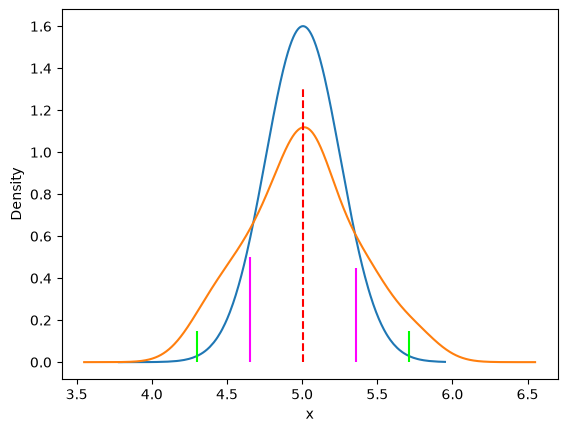

In [196]:
print(c1_setosa.describe())
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c1_setosa.mean() - 1 * c1_setosa.std(), c1_setosa.mean() + 1 * c1_setosa.std()],
    "95%": [c1_setosa.mean() - 2 * c1_setosa.std(), c1_setosa.mean() + 2 * c1_setosa.std()],
    "99.7%": [c1_setosa.mean() - 3 * c1_setosa.std(), c1_setosa.mean() + 3 * c1_setosa.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c1_setosa[(c1_setosa >= intervalos.iloc[0, 0]) & (c1_setosa <= intervalos.iloc[0, 1])].count() / c1_setosa.count():.0f}%")
print(f"95% | {100 * c1_setosa[(c1_setosa >= intervalos.iloc[1, 0]) & (c1_setosa <= intervalos.iloc[1, 1])].count() / c1_setosa.count():.0f}%")
print(f"99.7% | {100 * c1_setosa[(c1_setosa >= intervalos.iloc[2, 0]) & (c1_setosa <= intervalos.iloc[2, 1])].count() / c1_setosa.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c1_setosa.mean(), c1_setosa.std(), 1000)
y_normal = numpy.exp(-(x_normal - c1_setosa.mean()) ** 2 / c1_setosa.var()) / \
            (numpy.pi * c1_setosa.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c1_setosa.plot.density() # KDE
pyplot.vlines(c1_setosa.mean(), 0, 1.3, color="red", linestyle="--")
pyplot.vlines(c1_setosa.mean() - c1_setosa.std(), 0, 0.5, color="magenta", linestyle="-")
pyplot.vlines(c1_setosa.mean() + c1_setosa.std(), 0, 0.45, color="magenta", linestyle="-")
pyplot.vlines(c1_setosa.mean() - 2 * c1_setosa.std(), 0, 0.15, color="lime", linestyle="-")
pyplot.vlines(c1_setosa.mean() + 2 * c1_setosa.std(), 0, 0.15, color="lime", linestyle="-")
pyplot.show()

In [197]:
from scipy import stats

In [203]:

estadistico, p_valor = stats.shapiro(c1_setosa)

print(f"W:       {estadistico:.4f}")
print(f"P-Valor: {p_valor:.4f}")

print("-" * 60)

# Confianza del 5%
if p_valor >= 0.05:
    print("C1 - tiene una distribución normal")
else:
    print("C1 - no se comporta como una distribución normal")


W:       0.9777
P-Valor: 0.4595
------------------------------------------------------------
C1 - tiene una distribución normal


In [247]:
# C1 - Largo de sépalo

x = 5
mu_setosa = c1_setosa.mean()
sigma_setosa = c1_setosa.std()

# PDF - Probability Density Function
# !!! Supuesto: C1 es normal (tiene una distribución normal o casi normal)
# Indicamos qué tan cerca estamos del promedio (diferencia de densidades)
p = stats.norm.pdf(x, loc=mu_setosa, scale=sigma) / stats.norm.pdf(mu_setosa, loc=mu_setosa, scale=sigma)
#print(p)

# P(X > x)
# Indicamos qué tanto superamos a la media
# Inverse Cumulative Density Function
pa = stats.norm.sf(x - mu, loc=mu, scale=sigma)
#print(pa)

# P(X < x)
# Indicamos qué tanto no superamos a la media
# Cumulative Density Function
pb = 1 - stats.norm.cdf(mu - x, loc=mu, scale=sigma)
#print(pb)

print(f"{100 * p:.2f}% | {100 * (pa + pb) / 2:.2f}%")

100.00% | 95.78%


In [249]:
x = 5
mu_setosa = c1_versicolor.mean()
sigma_setosa = c1_versicolor.std()

# PDF - Probability Density Function
# !!! Supuesto: C1 es normal (tiene una distribución normal o casi normal)
# Indicamos qué tan cerca estamos del promedio (diferencia de densidades)
p = stats.norm.pdf(x, loc=mu_setosa, scale=sigma) / stats.norm.pdf(mu_setosa, loc=mu_setosa, scale=sigma)
#print(p)

# P(X > x)
# Indicamos qué tanto superamos a la media
# Inverse Cumulative Density Function
pa = stats.norm.sf(x - mu, loc=mu, scale=sigma)
#print(pa)

# P(X < x)
# Indicamos qué tanto no superamos a la media
# Cumulative Density Function
pb = 1 - stats.norm.cdf(mu - x, loc=mu, scale=sigma)
#print(pb)

print(f"{100 * p:.2f}% | {100 * (pa + pb) / 2:.2f}%")

96.74% | 95.78%


In [250]:
x = 5
mu_setosa = c1_virginica.mean()
sigma_setosa = c1_virginica.std()

# PDF - Probability Density Function
# !!! Supuesto: C1 es normal (tiene una distribución normal o casi normal)
# Indicamos qué tan cerca estamos del promedio (diferencia de densidades)
p = stats.norm.pdf(x, loc=mu_setosa, scale=sigma) / stats.norm.pdf(mu_setosa, loc=mu_setosa, scale=sigma)
#print(p)

# P(X > x)
# Indicamos qué tanto superamos a la media
# Inverse Cumulative Density Function
pa = stats.norm.sf(x - mu, loc=mu, scale=sigma)
#print(pa)

# P(X < x)
# Indicamos qué tanto no superamos a la media
# Cumulative Density Function
pb = 1 - stats.norm.cdf(mu - x, loc=mu, scale=sigma)
#print(pb)

print(f"{100 * p:.2f}% | {100 * (pa + pb) / 2:.2f}%")

90.89% | 95.78%


In [251]:
# Observación: (SL: 5, SW: 3, PL: 2, PW: 1.5)

SL = 5
SW = 3
PL = 2
PW = 1.5

mu_c1_setosa = c1_setosa.mean()
sigma_c1_setosa = c1_setosa.std()
mu_c2_setosa = c2_setosa.mean()
sigma_c2_setosa = c2_setosa.std()
mu_c3_setosa = c3_setosa.mean()
sigma_c3_setosa = c3_setosa.std()
mu_c4_setosa = c4_setosa.mean()
sigma_c4_setosa = c4_setosa.std()

In [252]:
mu_c1_versicolor = c1_versicolor.mean()
sigma_c1_versicolor = c1_versicolor.std()
mu_c2_versicolor = c2_versicolor.mean()
sigma_c2_versicolor = c2_versicolor.std()
mu_c3_versicolor = c3_versicolor.mean()
sigma_c3_versicolor = c3_versicolor.std()
mu_c4_versicolor = c4_versicolor.mean()
sigma_c4_versicolor = c4_versicolor.std()

In [253]:
mu_c1_virginica = c1_virginica.mean()
sigma_c1_virginica = c1_virginica.std()
mu_c2_virginica = c2_virginica.mean()
sigma_c2_virginica = c2_virginica.std()
mu_c3_virginica = c3_virginica.mean()
sigma_c3_virginica = c3_virginica.std()
mu_c4_virginica = c4_virginica.mean()
sigma_c4_virginica = c4_virginica.std()

In [258]:
pandas.DataFrame({
    "Setosa": [
        stats.norm.pdf(SL, loc=mu_c1_setosa, scale=sigma_c1_setosa) / stats.norm.pdf(mu_c1_setosa, loc=mu_c1_setosa, scale=sigma_c1_setosa),
        stats.norm.pdf(SW, loc=mu_c2_setosa, scale=sigma_c2_setosa) / stats.norm.pdf(mu_c2_setosa, loc=mu_c2_setosa, scale=sigma_c2_setosa),
        stats.norm.pdf(PL, loc=mu_c3_setosa, scale=sigma_c3_setosa) / stats.norm.pdf(mu_c3_setosa, loc=mu_c3_setosa, scale=sigma_c3_setosa),
        stats.norm.pdf(PW, loc=mu_c4_setosa, scale=sigma_c4_setosa) / stats.norm.pdf(mu_c4_setosa, loc=mu_c4_setosa, scale=sigma_c4_setosa),
    ],
    "Versicolor": [
        stats.norm.pdf(SL, loc=mu_c1_versicolor, scale=sigma_c1_versicolor) / stats.norm.pdf(mu_c1_versicolor, loc=mu_c1_versicolor, scale=sigma_c1_versicolor),
        stats.norm.pdf(SW, loc=mu_c2_versicolor, scale=sigma_c2_versicolor) / stats.norm.pdf(mu_c2_versicolor, loc=mu_c2_versicolor, scale=sigma_c2_versicolor),
        stats.norm.pdf(PL, loc=mu_c3_versicolor, scale=sigma_c3_versicolor) / stats.norm.pdf(mu_c3_versicolor, loc=mu_c3_versicolor, scale=sigma_c3_versicolor),
        stats.norm.pdf(PW, loc=mu_c4_versicolor, scale=sigma_c4_versicolor) / stats.norm.pdf(mu_c4_versicolor, loc=mu_c4_versicolor, scale=sigma_c4_versicolor),
    ],
    "Virginica": [
        stats.norm.pdf(SL, loc=mu_c1_virginica, scale=sigma_c1_virginica) / stats.norm.pdf(mu_c1_virginica, loc=mu_c1_virginica, scale=sigma_c1_virginica),
        stats.norm.pdf(SW, loc=mu_c2_virginica, scale=sigma_c2_virginica) / stats.norm.pdf(mu_c2_virginica, loc=mu_c2_virginica, scale=sigma_c2_virginica),
        stats.norm.pdf(PL, loc=mu_c3_virginica, scale=sigma_c3_virginica) / stats.norm.pdf(mu_c3_virginica, loc=mu_c3_virginica, scale=sigma_c3_virginica),
        stats.norm.pdf(PW, loc=mu_c4_virginica, scale=sigma_c4_virginica) / stats.norm.pdf(mu_c4_virginica, loc=mu_c4_virginica, scale=sigma_c4_virginica),
    ],
}, index=["sepal.length", "sepal.width", "petal.length", "petal.width"]).T.round(3)

,sepal.length,sepal.width,petal.length,petal.width
Setosa,1.000,0.529,0.008,0.000
Versicolor,0.193,0.764,0.000,0.679
Virginica,0.044,0.997,0.000,0.160


In [259]:
iris.sample(10)

,sepal.length,sepal.width,petal.length,petal.width,variety
60,5.0,2.0,3.5,1.0,Versicolor
115,6.4,3.2,5.3,2.3,Virginica
19,5.1,3.8,1.5,0.3,Setosa
116,6.5,3.0,5.5,1.8,Virginica
58,6.6,2.9,4.6,1.3,Versicolor
7,5.0,3.4,1.5,0.2,Setosa
47,4.6,3.2,1.4,0.2,Setosa
31,5.4,3.4,1.5,0.4,Setosa
79,5.7,2.6,3.5,1.0,Versicolor
18,5.7,3.8,1.7,0.3,Setosa


In [263]:
SL = 5.7
SW = 2.6
PL = 3.5
PW = 2

pandas.DataFrame({
    "Setosa": [
        stats.norm.pdf(SL, loc=mu_c1_setosa, scale=sigma_c1_setosa) / stats.norm.pdf(mu_c1_setosa, loc=mu_c1_setosa, scale=sigma_c1_setosa),
        stats.norm.pdf(SW, loc=mu_c2_setosa, scale=sigma_c2_setosa) / stats.norm.pdf(mu_c2_setosa, loc=mu_c2_setosa, scale=sigma_c2_setosa),
        stats.norm.pdf(PL, loc=mu_c3_setosa, scale=sigma_c3_setosa) / stats.norm.pdf(mu_c3_setosa, loc=mu_c3_setosa, scale=sigma_c3_setosa),
        stats.norm.pdf(PW, loc=mu_c4_setosa, scale=sigma_c4_setosa) / stats.norm.pdf(mu_c4_setosa, loc=mu_c4_setosa, scale=sigma_c4_setosa),
    ],
    "Versicolor": [
        stats.norm.pdf(SL, loc=mu_c1_versicolor, scale=sigma_c1_versicolor) / stats.norm.pdf(mu_c1_versicolor, loc=mu_c1_versicolor, scale=sigma_c1_versicolor),
        stats.norm.pdf(SW, loc=mu_c2_versicolor, scale=sigma_c2_versicolor) / stats.norm.pdf(mu_c2_versicolor, loc=mu_c2_versicolor, scale=sigma_c2_versicolor),
        stats.norm.pdf(PL, loc=mu_c3_versicolor, scale=sigma_c3_versicolor) / stats.norm.pdf(mu_c3_versicolor, loc=mu_c3_versicolor, scale=sigma_c3_versicolor),
        stats.norm.pdf(PW, loc=mu_c4_versicolor, scale=sigma_c4_versicolor) / stats.norm.pdf(mu_c4_versicolor, loc=mu_c4_versicolor, scale=sigma_c4_versicolor),
    ],
    "Virginica": [
        stats.norm.pdf(SL, loc=mu_c1_virginica, scale=sigma_c1_virginica) / stats.norm.pdf(mu_c1_virginica, loc=mu_c1_virginica, scale=sigma_c1_virginica),
        stats.norm.pdf(SW, loc=mu_c2_virginica, scale=sigma_c2_virginica) / stats.norm.pdf(mu_c2_virginica, loc=mu_c2_virginica, scale=sigma_c2_virginica),
        stats.norm.pdf(PL, loc=mu_c3_virginica, scale=sigma_c3_virginica) / stats.norm.pdf(mu_c3_virginica, loc=mu_c3_virginica, scale=sigma_c3_virginica),
        stats.norm.pdf(PW, loc=mu_c4_virginica, scale=sigma_c4_virginica) / stats.norm.pdf(mu_c4_virginica, loc=mu_c4_virginica, scale=sigma_c4_virginica),
    ],
}, index=["sepal.length", "sepal.width", "petal.length", "petal.width"]).T.round(3)

,sepal.length,sepal.width,petal.length,petal.width
Setosa,0.144,0.092,0.000,0.000
Versicolor,0.901,0.864,0.270,0.003
Virginica,0.377,0.510,0.001,0.996
